# 08 -- Full galaxy analysis, start to finish

**Goal:** this is the capstone notebook -- a complete, real analysis
combining every piece this notebook sequence has built and validated
separately:

1. An already-conditioned stellar template library (`04_template_calibration.ipynb`).
2. PA-aware dartboard spatial binning (`kinextract.binning`), matching
   a real, independently-verified reference binning scheme.
3. Sky-residual and emission-line masking (`05_real_data_muse.ipynb`).
4. Correlated-noise-aware whitening (`07_noise_correlation.ipynb`).
5. Parallel per-bin fitting *and* parallel bootstrap uncertainty --
   both genuinely necessary at this scale, not a demonstration toggle.
6. Real moment maps and radial kinematic profiles, built the way IFU
   kinematics papers actually build them.

Read this notebook as *the reason each earlier notebook exists*: every step
below is doing something a previous notebook motivated and tested in
isolation. If any step here is unclear, that earlier notebook is where the
explanation lives -- this one focuses on how they fit together.

**This is a genuinely large computation, not a quick demo.** Choose
`RMAX_ARCSEC` in Section 2 to cover as much of the field as you want
analyzed -- the default here (30\") is deliberately the *real* science
radius, not a coarsened stand-in, and follows the same dartboard geometry
`dev_notes/scratch_notebooks/ppxf_vs_kinextract_comparison.ipynb` uses for
its own real-data comparison (239 bins at this radius). At that scale,
bootstrap uncertainty (many refits *per bin*) is the dominant cost --
measured directly on this data: ~33s/bin serially, ~17s/bin with
`bootstrap_losvd_parallel` at `n_jobs=4` (roughly halved, not perfectly
divided by 4 -- worker-startup and JIT-warmup costs don't fully amortize;
see that function's own docstring). Expect on the order of an hour for the
default 30\" radius; **results are cached to disk** (Section 3) so this
only needs to run once per configuration -- change `RMAX_ARCSEC` or any
other binning/fit choice and it recomputes automatically; leave everything
the same and it loads instantly from the cache instead.

In [1]:
import sys, os, time, pickle, warnings
from pathlib import Path
SRC_DIR = "../../src"
sys.path.insert(0, SRC_DIR)

import numpy as np
import matplotlib.pyplot as plt

from kinextract import (
    FitConfig, build_template_stack, compute_losvd_moments, mask_wavelength_windows,
    load_emiles_templates, load_muse_cube, extract_aperture_spectrum, white_light_image,
    bootstrap_losvd_parallel, detect_emission_lines, gauss_hermite_model,
    fit_losvd_clean_parallel,
    DartboardBins, build_reflected_sin_theta_edges, assign_spaxels_to_bins,
)
from kinextract.multi_template import fit_losvd
from kinextract.template_reduction import load_template_subset
from kinextract.noise_model import whiten

import kinextract
print(f"kinextract loaded from: {kinextract.__file__}")

CACHE_DIR = Path("cache")
CACHE_DIR.mkdir(exist_ok=True)

kinextract loaded from: /Users/waterstk/Documents/Gultekin_Astrophysics/kinextract_lite/examples/notebooks/../../src/kinextract/__init__.py


In [2]:
import matplotlib.patches as mpatches


def plot_bin_map(ax, bin_table, bins, values_by_bin_id, center_pix, pa_deg, pixel_scale,
                  background=None, cmap="RdBu_r", vmin=None, vmax=None,
                  grid_color="black", grid_lw=0.5, grid_alpha=0.6, colorbar_label=None,
                  add_cbar=True):
    """Paints each populated dartboard bin as a filled wedge at its real
    sky position/extent, with explicit grid-line boundaries drawn on top --
    replaces `imshow(paint_map(...))`: a discrete per-pixel raster plus a
    continuous colormap gives adjacent bins with similar values no visual
    separation at all, and bin edges only show up as raster jaggedness,
    not a real line. `background` (e.g. the white-light image), if given,
    is drawn underneath at reduced alpha for spatial context -- the same
    idea as overlaying kinematic maps on a galaxy image in a real paper
    figure.
    """
    bx, by = center_pix
    if background is not None:
        ax.imshow(background, origin="lower", cmap="gray", alpha=0.35, zorder=0)

    vals_present = np.array([v for v in values_by_bin_id.values() if np.isfinite(v)])
    if vmin is None:
        vmin = -np.nanmax(np.abs(vals_present)) if cmap == "RdBu_r" else np.nanmin(vals_present)
    if vmax is None:
        vmax = np.nanmax(np.abs(vals_present)) if cmap == "RdBu_r" else np.nanmax(vals_present)
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    cmap_obj = plt.get_cmap(cmap)

    for row in bin_table:
        bid = row["bin_id"]
        if bid not in values_by_bin_id:
            continue
        color = cmap_obj(norm(values_by_bin_id[bid]))
        if row["theta_mid"] is None:
            # collapsed center bin -- a full circle out to the first radial edge
            r_hi = bins.r_edges[1] / pixel_scale
            wedge = mpatches.Wedge((bx, by), r_hi, 0.0, 360.0, facecolor=color,
                                    edgecolor="none", zorder=1)
        else:
            r_lo = bins.r_edges[row["r_index"]] / pixel_scale
            r_hi = bins.r_edges[row["r_index"] + 1] / pixel_scale
            # local (PA-relative) angle -> sky angle, matching assign_spaxels_to_bins's
            # own rotation convention exactly (binning.py: sky = R(+pa) @ local)
            theta_lo = np.degrees(bins.theta_edges[row["theta_index"]]) + pa_deg
            theta_hi = np.degrees(bins.theta_edges[row["theta_index"] + 1]) + pa_deg
            wedge = mpatches.Wedge((bx, by), r_hi, theta_lo, theta_hi, width=r_hi - r_lo,
                                    facecolor=color, edgecolor="none", zorder=1)
        ax.add_patch(wedge)

    # grid lines drawn separately from the fill, so bin boundaries stay
    # crisp regardless of how similar two neighboring bins' colors are
    # r_edges[0] isn't a real bin boundary (the collapsed center bin's own
    # outer edge is r_edges[1] -- see the fill loop above), so skip it here
    # too, or it draws a small, meaningless circle inside the center bin
    t = np.linspace(0.0, 2 * np.pi, 400)
    for r_edge in bins.r_edges[1:]:
        rp = r_edge / pixel_scale
        ax.plot(bx + rp * np.cos(t), by + rp * np.sin(t), color=grid_color,
                lw=grid_lw, alpha=grid_alpha, zorder=2)
    # angular spokes start at the *center bin's own* outer edge (r_edges[1] --
    # matching the collapsed-center-bin fill above, not r_edges[0]/the true
    # center), so the innermost bin renders as a plain undivided circle
    # instead of looking cut into wedges
    r_inner_pix = bins.r_edges[1] / pixel_scale
    r_max_pix = bins.r_edges[-1] / pixel_scale
    for theta_edge in bins.theta_edges:
        th = theta_edge + np.radians(pa_deg)
        ax.plot([bx + r_inner_pix * np.cos(th), bx + r_max_pix * np.cos(th)],
                [by + r_inner_pix * np.sin(th), by + r_max_pix * np.sin(th)],
                color=grid_color, lw=grid_lw, alpha=grid_alpha, zorder=2)

    if add_cbar:
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_obj)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, fraction=0.046)
        if colorbar_label:
            cbar.set_label(colorbar_label)
    ax.set_aspect("equal")

## 1. Load the cube and the already-conditioned template library

A real E-MILES grid has hundreds of age/metallicity combinations -- far more
free parameters than any one spectrum's own S/N can usefully constrain, and
degenerate template mixtures are a real, measured source of bias (see
`03_emiles_templates.ipynb`). `04_template_calibration.ipynb` solves this
once, for the whole target, by iteratively fitting every dartboard bin
against the full grid and keeping only the templates whose NNLS weight
actually survives somewhere -- `ngc5102_template_subset.npz`'s
`union_selected`. This notebook reuses that output directly rather than
re-deriving it: conditioning is a per-target, do-it-once step, not something
a downstream analysis notebook should redo on every run.

cube: (3681, 317, 318) (n_wave, ny, nx), pixel_scale=0.20000000000000015"
loaded 9 conditioned templates (of the full E-MILES grid):
  Ebi1.30Zm0.35T06.5000_iTp0.00_baseFe.fits  age=6.50 Gyr  [M/H]=-0.35
  Ebi1.30Zm0.35T07.0000_iTp0.00_baseFe.fits  age=7.00 Gyr  [M/H]=-0.35
  Ebi1.30Zm0.35T07.5000_iTp0.00_baseFe.fits  age=7.50 Gyr  [M/H]=-0.35
  Ebi1.30Zm0.66T00.0300_iTp0.00_baseFe.fits  age=0.03 Gyr  [M/H]=-0.66
  Ebi1.30Zp0.15T00.0300_iTp0.00_baseFe.fits  age=0.03 Gyr  [M/H]=+0.15
  Ebi1.30Zp0.15T00.0400_iTp0.00_baseFe.fits  age=0.04 Gyr  [M/H]=+0.15
  Ebi1.30Zp0.15T02.7500_iTp0.00_baseFe.fits  age=2.75 Gyr  [M/H]=+0.15
  Ebi1.30Zp0.15T03.5000_iTp0.00_baseFe.fits  age=3.50 Gyr  [M/H]=+0.15
  Ebi1.30Zp0.26T03.0000_iTp0.00_baseFe.fits  age=3.00 Gyr  [M/H]=+0.26


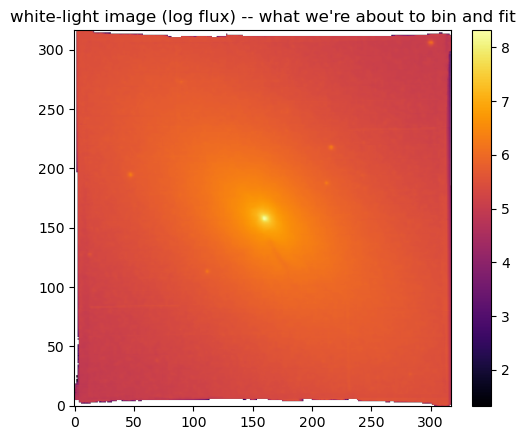

In [3]:
CUBE_PATH = "muse_download/ADP.2017-03-22T15:25:58.757.fits"
TEMPLATE_SUBSET_PATH = "../data/muse/ngc5102_template_subset.npz"
EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"
Z = 468.0 / 299792.458  # NGC 5102 systemic velocity ~468 km/s (NED)

if not os.path.exists(CUBE_PATH):
    raise FileNotFoundError(
        f"{CUBE_PATH} not found -- see 04_template_calibration.ipynb's DATA_MODE cell "
        "to download it (or point CUBE_PATH at any other MUSE Phase 3 cube)."
    )

cube = load_muse_cube(CUBE_PATH)
ny, nx = cube.shape
print(f"cube: {cube.flux.shape} (n_wave, ny, nx), pixel_scale={cube.pixel_scale}\"")

subset = load_template_subset(TEMPLATE_SUBSET_PATH)
union_idx = subset["union_selected"]
select = list(zip(subset["template_ages"][union_idx].tolist(), subset["template_metals"][union_idx].tolist()))
templates, template_wave, names, ages, metals = load_emiles_templates(EMILES_GRID, select=select)
print(f"loaded {len(templates)} conditioned templates (of the full E-MILES grid):")
for n, a, m in zip(names, ages, metals):
    print(f"  {n}  age={a:.2f} Gyr  [M/H]={m:+.2f}")

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
    white_light = white_light_image(cube)
fig, ax = plt.subplots(figsize=(5, 4.5))
with np.errstate(divide="ignore", invalid="ignore"):
    log_white_light = np.where(white_light > 0, np.log10(white_light), np.nan)
im = ax.imshow(log_white_light, origin="lower", cmap="inferno")
ax.set_title("white-light image (log flux) -- what we're about to bin and fit")
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

## 2. PA-aware dartboard binning -- choose your own `RMAX_ARCSEC`

A single spaxel's own S/N falls off fast away from the nucleus -- too low,
on its own, to usefully constrain a LOSVD shape (`05_real_data_muse.ipynb`'s
own low-S/N aperture, for example, cannot support h3/h4 at all). Spatial
binning trades resolution for S/N by combining many faint spaxels into one
spectrum per bin.

**Why PA-aware, specifically.** `kinextract.binning`'s own default
(`uniform_theta_edges`) bins equal in angle, with no assumed axis -- the
right choice when nothing about the target's orientation is known yet.
Here we *do* know NGC 5102's kinematic major axis, so this notebook uses
`build_reflected_sin_theta_edges` + `assign_spaxels_to_bins`'s `pa_deg`
parameter instead: sectors come out narrowest along the major axis (where
rotation actually shows up in the LOSVD) and widest along the minor axis
(where it doesn't) -- concentrating angular resolution exactly where it's
useful. `REFERENCE_R_EDGES_ARCSEC` and `N_THETA_PER_QUADRANT=5` below match
an independent reference binning scheme exactly (`bin_r.out`/
`bin_v.out`'s own edges; see `binning.py`'s module docstring for the
verification), rescaled to this cube's field of view and truncated at
whatever `RMAX_ARCSEC` you choose.

**`RMAX_ARCSEC` is the one parameter you're meant to change.** Larger
values cover more of the field at the cost of more bins (and therefore
more bootstrap wall-clock, the dominant cost -- see the intro markdown
above). The default (30\") is a real science radius on this target, not a
coarsened demo -- change it here, then re-run from this cell down; a
different value invalidates the cache automatically (Section 3).

219 populated bins (17 radial x 20 angular) out to r=28.53" (requested RMAX_ARCSEC=29.66", snapped down to the nearest real bin edge -- no partial sliver ring)


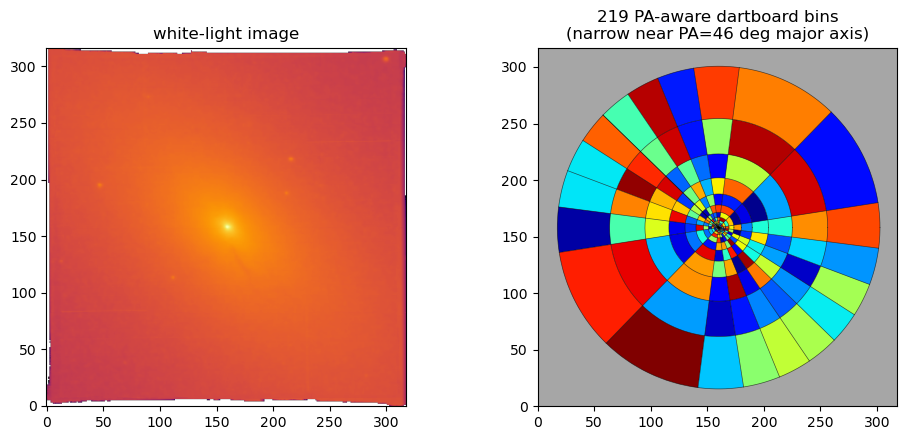

In [4]:
PA_DEG = 45.77 + 90.0       # NGC 5102's own kinematic major-axis PA
N_THETA_PER_QUADRANT = 5    # matches an independent reference bin_v.out exactly
REFERENCE_R_EDGES_ARCSEC = np.array([
    0.021, 0.048, 0.088, 0.147, 0.235, 0.365, 0.557, 0.841, 1.261, 1.883,
    2.801, 4.160, 6.171, 9.143, 13.540, 20.044, 29.662, 43.888,
])  # an independent reference dataset's own radial bin edges (bin_r.out's "rup" column) -- rescaled/truncated below

RMAX_ARCSEC = REFERENCE_R_EDGES_ARCSEC[-2]          # <-- the parameter to change; radial coverage in arcsec


with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="All-NaN slice encountered", category=RuntimeWarning)
    signal_map = np.nanmedian(cube.flux, axis=0)
    noise_map = np.nanmedian(cube.error, axis=0)
good0 = np.isfinite(signal_map) & np.isfinite(noise_map) & (signal_map > 0) & (noise_map > 0)

by, bx = np.unravel_index(np.nanargmax(np.where(good0, signal_map, np.nan)), signal_map.shape)
x_arcsec = (np.arange(nx) - bx) * cube.pixel_scale
y_arcsec = (np.arange(ny) - by) * cube.pixel_scale
xx, yy = np.meshgrid(x_arcsec, y_arcsec)
r_arcsec = np.hypot(xx, yy)
good = good0 & (r_arcsec <= RMAX_ARCSEC)

# rescale the reference radial edges to this cube's own field of view, then truncate at RMAX_ARCSEC
fov_half_extent = 0.5 * min(nx, ny) * cube.pixel_scale
r_edges_full = REFERENCE_R_EDGES_ARCSEC * (0.9 * fov_half_extent / REFERENCE_R_EDGES_ARCSEC[-1])
# Snap DOWN to the nearest real (rescaled) reference edge <= RMAX_ARCSEC --
# never append RMAX_ARCSEC itself as a brand-new edge. The old version did
# that unconditionally whenever r_edges_full's last kept entry fell short of
# RMAX_ARCSEC, which is *every* time RMAX_ARCSEC isn't an exact rescaled
# edge value -- e.g. RMAX_ARCSEC = one of REFERENCE_R_EDGES_ARCSEC's own
# (unscaled) entries looks like it should land exactly on a real edge, but
# r_edges_full is REFERENCE_R_EDGES_ARCSEC*scale_factor, a *different* set
# of numbers -- so it silently created a partial sliver ring (observed
# directly: RMAX_ARCSEC=REFERENCE_R_EDGES_ARCSEC[-2] produced a final ring
# only ~1.1 arcsec wide, versus ~9 arcsec for the ring just inside it).
r_edges = r_edges_full[r_edges_full <= RMAX_ARCSEC]
if len(r_edges) < 2:
    r_edges = r_edges_full[:2]

theta_edges = build_reflected_sin_theta_edges(N_THETA_PER_QUADRANT)
bins = DartboardBins(r_edges=r_edges, theta_edges=theta_edges, center=(bx, by))
bin_id_map, bin_table = assign_spaxels_to_bins((ny, nx), bins, pixel_scale=cube.pixel_scale, pa_deg=PA_DEG)
bin_id_map[~good] = -1
bin_table = [row for row in bin_table if np.any(bin_id_map == row["bin_id"])]
bin_ids = [row["bin_id"] for row in bin_table]
n_bins = len(bin_table)

print(f"{n_bins} populated bins ({bins.n_radial} radial x {bins.n_angular} angular) "
      f"out to r={r_edges[-1]:.2f}\" (requested RMAX_ARCSEC={RMAX_ARCSEC:.2f}\", "
      f"snapped down to the nearest real bin edge -- no partial sliver ring)")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
with np.errstate(divide="ignore", invalid="ignore"):
    log_white_light = np.where(white_light > 0, np.log10(white_light), np.nan)
axes[0].imshow(log_white_light, origin="lower", cmap="inferno")
axes[0].set_title("white-light image")
# random (not spatially-ordered) color per bin -- tab20 cycles through only 20
# colors, so with 239 bins many *adjacent* wedges land on the same or a
# similar swatch; a random permutation over a wide-gamut colormap instead
# makes neighboring bins land on unrelated colors almost always, which is
# the property that actually matters for "can I tell bins apart"
_bin_color_rng = np.random.default_rng(0)
_random_bin_value = {bid: v for bid, v in zip(bin_ids, _bin_color_rng.permutation(len(bin_ids)))}
plot_bin_map(axes[1], bin_table, bins, _random_bin_value, center_pix=bins.center,
             pa_deg=PA_DEG, pixel_scale=cube.pixel_scale, background=white_light,
             cmap="jet", vmin=0, vmax=len(bin_ids) - 1, add_cbar=False)
axes[1].set_xlim(0, nx); axes[1].set_ylim(0, ny)
axes[1].set_title(f"{n_bins} PA-aware dartboard bins\n(narrow near PA={PA_DEG-90:.0f} deg major axis)")
plt.tight_layout(); plt.show()

## 3. Caching -- this run only needs to happen once per configuration

Everything below (masking, fitting, bootstrap) is deterministic given the
binning geometry, template selection, `rho`, and bootstrap settings -- so
this cell fingerprints all of that into one `CACHE_TAG` and, if a matching
result already exists on disk, loads it instantly instead of recomputing.
Change `RMAX_ARCSEC` (or any other setting in Section 2, or `MEASURED_RHO`/
`N_BOOT` below) and the tag changes, so a new configuration always
recomputes rather than silently reusing a stale result for a different
question.

In [5]:
MEASURED_RHO = 0.88  # from 07_noise_correlation.ipynb -- re-measure for your own target
N_BOOT = 15
BOOT_SEED = 0
N_JOBS = 4  # measured faster than n_jobs=None (os.cpu_count()) on this machine's
            # performance/efficiency core mix -- see fit_losvd_parallel's own docstring
CLIP_SIGMA = 3.0     # fit_losvd_clean's clip threshold (in robust-scaled units -- see Section 4)
MAX_ITER = 3         # fit_losvd_clean's max refit iterations
ROBUST_SCALE = True  # see Section 4 markdown for why this matters on real data

CACHE_TAG = (f"rmax{RMAX_ARCSEC:.1f}_pa{PA_DEG:.1f}_nt{N_THETA_PER_QUADRANT}_nb{n_bins}_rho{MEASURED_RHO:.2f}"
             f"_nboot{N_BOOT}_seed{BOOT_SEED}_clip{CLIP_SIGMA:.1f}_iter{MAX_ITER}_robust{ROBUST_SCALE}")
CACHE_PATH = CACHE_DIR / f"full_galaxy_{CACHE_TAG}.pkl"
print(f"cache key: {CACHE_TAG}")
print(f"cache path: {CACHE_PATH}  (exists: {CACHE_PATH.exists()})")

cache key: rmax29.7_pa135.8_nt5_nb219_rho0.88_nboot15_seed0_clip3.0_iter3_robustTrue
cache path: cache/full_galaxy_rmax29.7_pa135.8_nt5_nb219_rho0.88_nboot15_seed0_clip3.0_iter3_robustTrue.pkl  (exists: False)


## 4. Per-bin masking, fitting, and bootstrap uncertainty

Three things happen per bin:

- **Sky-residual and emission-line masking** (`05_real_data_muse.ipynb`,
  `cleaning.detect_emission_lines`): OH-airglow residual windows are a
  fixed, known-bad wavelength list; emission contamination is data-driven
  -- whether a candidate line is actually in emission depends on the
  spectrum, so it's re-checked per bin rather than masked unconditionally.
- **Iterative sigma-clipping, robust-scaled, as the default cleaning step**
  (`fit_losvd_clean_parallel(..., robust_scale=True)`). An earlier version
  of this notebook deliberately skipped cleaning entirely -- tested once
  at the default (non-robust) settings and found it clipped 90%+ of pixels
  in real bins and collapsed to a biased, unconstrained baseline. Root
  cause, found afterward: the default clip threshold is measured against
  the *input* noise vector, assuming it's correctly calibrated (chi2_red
  ~ 1); real chi2_red on this target runs 11-28
  (`07_noise_correlation.ipynb`), so a nominal "3 sigma" cut was actually
  under 1 *true* sigma almost everywhere, not just at the genuine
  contamination. `robust_scale=True` instead measures `CLIP_SIGMA` against
  a MAD-based robust estimate of the *current* residual's own scale
  (recomputed each iteration from the surviving pixels) -- confirmed
  directly on the worst-affected real bins here to behave far better:
  realistic clip fractions, no runaway, and a cleaned fit that actually
  tracks the data's real continuum shape between contaminated regions
  instead of collapsing flat.

  **This still needs real per-target tuning, not a fire-and-forget
  default** -- `CLIP_SIGMA`/`MAX_ITER` above are a starting point, not a
  validated universal choice: too aggressive a `CLIP_SIGMA` risks clipping
  into real absorption features (the CaII triplet in particular, if a
  contaminating line sits close to one), and this method has no way to
  distinguish a genuine narrow contaminant from a region where the
  *continuum shape itself* is wrong (e.g. an imperfect sky subtraction
  that biases the local continuum level rather than adding a narrow
  spike) -- that failure mode isn't fixed by any per-pixel clipping
  threshold. See `dev_notes/scratch_notebooks/cleaning_tuning.ipynb` for
  the sandbox this was tuned in and a fuller account of what was tried.
- **Two-stage fitting, in parallel** (`fit_losvd_clean_parallel`): a
  generous `+-400 km/s` wide pass locates `V`/`sigma` roughly (cheap, run
  serially below, no cleaning needed at this stage), then a properly
  centered `V +- 7*sigma` grid is where `FitConfig`'s actual choices
  (regularization, `rho`, ...) and cleaning both apply -- fit across
  *all* bins at once, parallelized the same way `fit_losvd_parallel` is.
- **Bootstrap uncertainty, in parallel** (`bootstrap_losvd_parallel`), on
  the *cleaned* pixel set each bin's own fit actually converged on -- not
  the original full set, so a bootstrap replicate's synthetic noise never
  gets added back at a position cleaning already excluded as contaminated.

In [6]:
import sys
import kinextract
import kinextract.aic_regularization

sys.modules["kinextract_lite"] = kinextract
sys.modules["kinextract_lite.aic_regularization"] = kinextract.aic_regularization

In [7]:
if CACHE_PATH.exists():
    print(f"loading cached result from {CACHE_PATH} ...")
    with open(CACHE_PATH, "rb") as f:
        bin_data = pickle.load(f)
    print(f"loaded {len(bin_data)} bins from cache -- skipping the fit/bootstrap below entirely")
else:
    WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0
    SKY_RESIDUAL_WINDOWS = [
        (8414.0, 8419.0), (8449.0, 8454.0), (8711.0, 8714.0), (8748.5, 8753.0),
    ]
    NSIG = 7

    t_start = time.time()
    bin_data = {}
    A_stack_w_list, y_w_list, cfg_list = [], [], []

    print(f"preparing and wide-pass-fitting {n_bins} bins (serial, cheap)...")
    for row in bin_table:
        bin_id = row["bin_id"]
        spaxel_mask = bin_id_map == bin_id
        wave_obs, flux_obs, error_obs = extract_aperture_spectrum(cube, spaxel_mask)
        wave_rest = wave_obs / (1.0 + Z)
        in_window = (wave_rest >= WAVEFITMIN) & (wave_rest <= WAVEFITMAX)
        wave_w, flux_w, error_w = wave_rest[in_window], flux_obs[in_window], error_obs[in_window]

        emission_windows = detect_emission_lines(wave_w, flux_w, error_w)
        all_windows = SKY_RESIDUAL_WINDOWS + emission_windows
        wave_fit, flux_fit = mask_wavelength_windows(wave_w, flux_w, windows=all_windows)
        _, errors = mask_wavelength_windows(wave_w, error_w, windows=all_windows)

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", UserWarning)
            cfg_wide = FitConfig(vmin=-400.0, vmax=400.0)
        v_grid_wide = cfg_wide.build_velocity_grid()
        A_stack_wide = build_template_stack(wave_fit, template_wave, templates, v_grid_wide)
        y_w_wide = flux_fit / errors
        result_wide = fit_losvd(A_stack_wide / errors[None, :, None], y_w_wide, cfg_wide)
        mw = compute_losvd_moments(v_grid_wide, result_wide["b"], fit_h3h4=False)

        cfg = FitConfig(vmin=mw["vherm"] - NSIG * mw["sherm"], vmax=mw["vherm"] + NSIG * mw["sherm"],
                         rho=MEASURED_RHO)
        v_grid = cfg.build_velocity_grid()
        A_stack = build_template_stack(wave_fit, template_wave, templates, v_grid)
        A_stack_w, y_w, L = whiten(A_stack, flux_fit, errors, rho=cfg.rho)

        A_stack_w_list.append(A_stack_w); y_w_list.append(y_w); cfg_list.append(cfg)
        bin_data[bin_id] = dict(wave_fit=wave_fit, flux_fit=flux_fit, errors=errors,
                                 n_spaxels=int(spaxel_mask.sum()),
                                 n_emission_windows=len(emission_windows),
                                 v_grid=v_grid, L=L,
                                 r_mid=row["r_mid"], theta_mid=row["theta_mid"])
    t_wide = time.time() - t_start
    n_with_emission = sum(1 for b in bin_data.values() if b["n_emission_windows"] > 0)
    print(f"  done in {t_wide:.0f}s ({n_with_emission} bins with detected emission)")

    print(f"fitting {n_bins} bins in parallel with cleaning (n_jobs={N_JOBS}, "
          f"clip_sigma={CLIP_SIGMA}, robust_scale={ROBUST_SCALE})...")
    t0 = time.time()
    results = fit_losvd_clean_parallel(A_stack_w_list, y_w_list, cfg_list, clip_sigma=CLIP_SIGMA,
                                        max_iter=MAX_ITER, robust_scale=ROBUST_SCALE, n_jobs=N_JOBS)
    t_fit = time.time() - t0
    print(f"  done in {t_fit:.0f}s ({t_fit/n_bins:.1f}s/bin)")

    for bin_id, result, A_stack_w in zip(bin_ids, results, A_stack_w_list):
        bd = bin_data[bin_id]
        bd["result"] = result
        bd["moments"] = compute_losvd_moments(bd["v_grid"], result["b"], fit_h3h4=True)
        bd["clipped_mask"] = result["clipped_mask"]
        bd["n_clipped"] = result["n_clipped"]
        # full-pixel model for plotting -- w/b are global, so apply them to every
        # pixel (including clipped ones), not just the surviving subset, so later
        # sections can show the whole spectrum with clipped points marked
        A_eff_full = np.tensordot(result["w"], A_stack_w, axes=([0], [0]))
        bd["model"] = bd["L"] @ (A_eff_full @ result["b"])

    n_clipped_total = sum(bd["n_clipped"] for bd in bin_data.values())
    n_pix_total = sum(len(bd["errors"]) for bd in bin_data.values())
    per_bin_frac = [bd["n_clipped"] / len(bd["errors"]) for bd in bin_data.values()]
    print(f"  cleaning clipped {n_clipped_total}/{n_pix_total} pixels overall "
          f"({100*n_clipped_total/n_pix_total:.1f}%), median {np.median(per_bin_frac):.1%} per bin, "
          f"max {np.max(per_bin_frac):.1%} per bin")

    print(f"bootstrapping {n_bins} bins in parallel (n_jobs={N_JOBS}, n_boot={N_BOOT})...")
    t0 = time.time()
    # bootstrap on each bin's own *cleaned* pixel set (matching what its point
    # estimate actually converged on), not the original full one -- otherwise a
    # bootstrap replicate's synthetic noise gets added back at positions cleaning
    # already excluded, reintroducing the exact problem cleaning fixed
    A_stack_w_clean_list = [A_stack_w_list[i][:, ~bin_data[bid]["clipped_mask"], :]
                             for i, bid in enumerate(bin_ids)]
    y_w_clean_list = [y_w_list[i][~bin_data[bid]["clipped_mask"]] for i, bid in enumerate(bin_ids)]
    boots = bootstrap_losvd_parallel(A_stack_w_clean_list, y_w_clean_list, cfg_list, n_boot=N_BOOT,
                                      seed=BOOT_SEED, n_jobs=N_JOBS)
    t_boot = time.time() - t0
    print(f"  done in {t_boot:.0f}s ({t_boot/n_bins:.1f}s/bin)")

    for bin_id, boot in zip(bin_ids, boots):
        bd = bin_data[bin_id]
        bd["sherm_std"] = boot["sherm_std"]
        bd["vherm_std"] = boot["vherm_std"]
        bd["h3_std"] = boot["h3_std"]
        bd["h4_std"] = boot["h4_std"]

    t_total = time.time() - t_start
    print(f"total: {t_total/60:.1f} min for {n_bins} bins")

    with open(CACHE_PATH, "wb") as f:
        pickle.dump(bin_data, f)
    print(f"cached to {CACHE_PATH}")

preparing and wide-pass-fitting 219 bins (serial, cheap)...


  done in 620s (186 bins with detected emission)
fitting 219 bins in parallel with cleaning (n_jobs=4, clip_sigma=3.0, robust_scale=True)...


<string>:27: UserWarning: FitConfig with vmin=-233.03466496718795, vmax=273.3084998337058 resolves to a knot spacing of 29.8 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 104515 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


<string>:27: UserWarning: FitConfig with vmin=-245.5024894527468, vmax=244.42460456398217 resolves to a knot spacing of 28.8 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 108017 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


<string>:27: UserWarning: FitConfig with vmin=-253.31563328464358, vmax=279.29742167442726 resolves to a knot spacing of 31.3 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 99360 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


<string>:27: UserWarning: FitConfig with vmin=-253.31563328464358, vmax=279.29742167442726 resolves to a knot spacing of 31.3 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 99360 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


... (677 outputs left out)

<string>:27: UserWarning: FitConfig with vmin=-228.0398292607011, vmax=232.35447102376273 resolves to a knot spacing of 27.1 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 114946 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


<string>:27: UserWarning: FitConfig with vmin=-228.0398292607011, vmax=232.35447102376273 resolves to a knot spacing of 27.1 km/s -- much finer than the 95 km/s `knot_spacing_kms` is calibrated against (this happens when the grid is narrow enough that `min_interior_knots` sets the knot count, not `knot_spacing_kms`). Because the curvature penalty is scaled by real velocity spacing (see `kinextract.losvd.difference_matrix`), this makes lam=32768.0 behave like an effective lam of 114946 -- confirmed to cause severe oversmoothing (>100% sigma bias) at this kind of extreme scale factor in validation testing. This does not happen at the validated NSIG=7 velocity-grid convention (`vmin/vmax = V -+ 7*sigma`) even down to sigma~20 km/s -- it means this grid is unusually narrow for its `min_interior_knots`. Consider a wider grid, a smaller `min_interior_knots`, or an explicit `n_interior_knots` override.


  done in 8253s (37.7s/bin)
total: 166.9 min for 219 bins


cached to cache/full_galaxy_rmax29.7_pa135.8_nt5_nb219_rho0.88_nboot15_seed0_clip3.0_iter3_robustTrue.pkl


## 5. A few example bins, before trusting the aggregate

Same discipline `dev_notes/scratch_notebooks/ppxf_vs_kinextract_comparison.ipynb`
uses: look at individual spectral fits and their extracted LOSVDs directly,
not just the summary numbers, before trusting a map or profile built from
all of them.

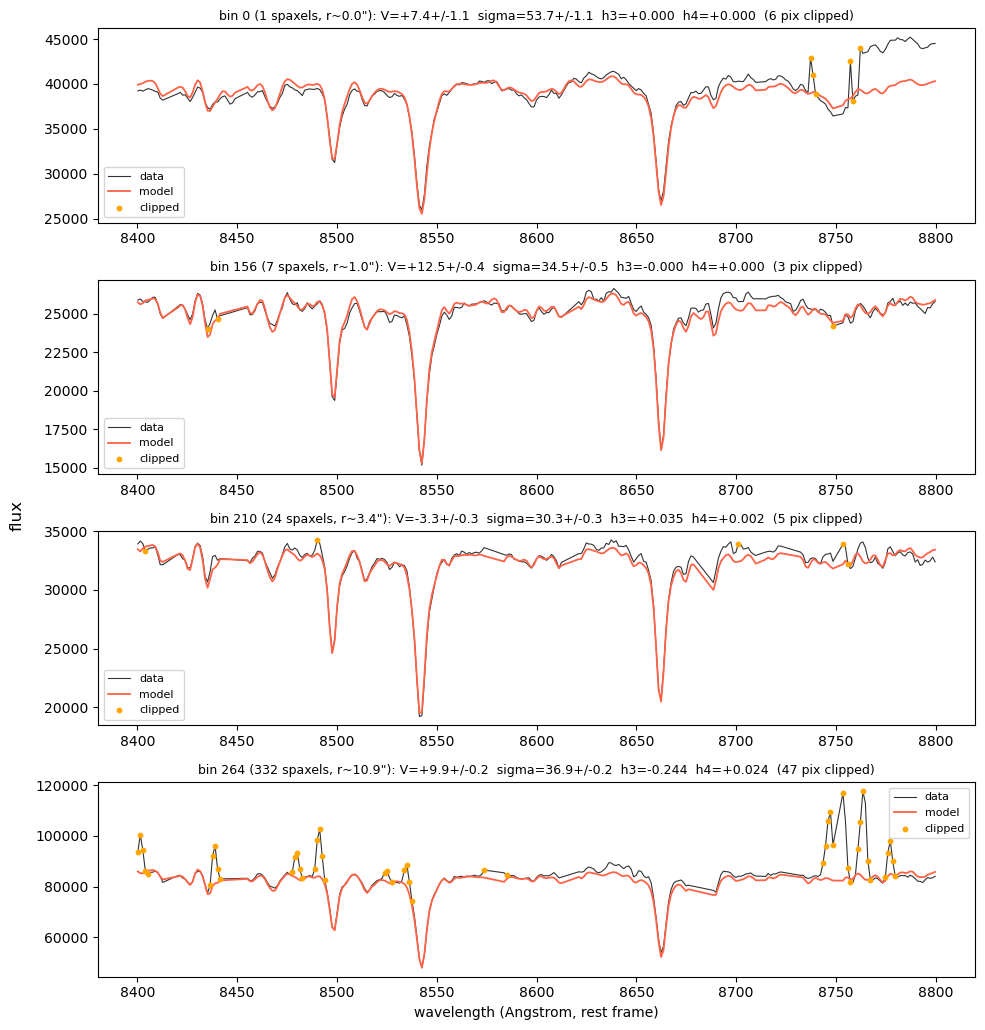

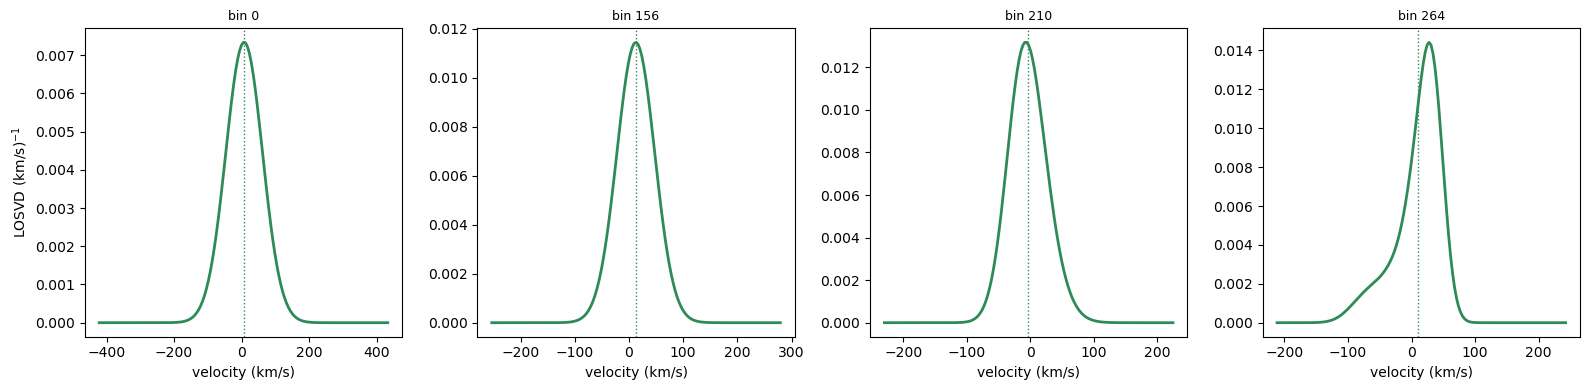

In [8]:
example_ids = sorted(bin_ids)[:: max(1, len(bin_ids) // 4)][:4]

fig, axes = plt.subplots(len(example_ids), 1, figsize=(10, 2.6 * len(example_ids)), sharex=False)
axes = np.atleast_1d(axes)
for ax, bid in zip(axes, example_ids):
    bd = bin_data[bid]
    ax.plot(bd["wave_fit"], bd["flux_fit"], color="black", lw=0.8, alpha=0.8, label="data")
    ax.plot(bd["wave_fit"], bd["model"], color="tomato", lw=1.3, label="model")
    clipped = bd["clipped_mask"]
    if np.any(clipped):
        ax.scatter(bd["wave_fit"][clipped], bd["flux_fit"][clipped], color="orange", s=10,
                   zorder=5, label="clipped")
    m = bd["moments"]
    ax.set_title(f"bin {bid} ({bd['n_spaxels']} spaxels, r~{bd['r_mid']:.1f}\"): "
                 f"V={m['vherm']:+.1f}+/-{bd['vherm_std']:.1f}  sigma={m['sherm']:.1f}+/-{bd['sherm_std']:.1f}  "
                 f"h3={m['h3']:+.3f}  h4={m['h4']:+.3f}  ({bd['n_clipped']} pix clipped)",
                 fontsize=9)
    ax.legend(fontsize=8)
axes[-1].set_xlabel("wavelength (Angstrom, rest frame)")
fig.supylabel("flux")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(example_ids), figsize=(4.0 * len(example_ids), 4), sharey=False)
axes = np.atleast_1d(axes)
for ax, bid in zip(axes, example_ids):
    bd = bin_data[bid]
    v_grid = bd["v_grid"]
    b_n = bd["result"]["b"] / np.trapezoid(np.maximum(bd["result"]["b"], 0.0), v_grid)
    ax.plot(v_grid, b_n, color="seagreen", lw=2.0)
    ax.axvline(bd["moments"]["vherm"], color="seagreen", ls=":", lw=1.0)
    ax.set_title(f"bin {bid}", fontsize=9)
    ax.set_xlabel("velocity (km/s)")
axes[0].set_ylabel(r"LOSVD (km/s)$^{-1}$")
plt.tight_layout(); plt.show()

## 6. Moment maps

**This is the point of doing spatial binning in the first place**, and it's
worth building properly. Every bin's spectrum represents *every spaxel that
went into it equally* -- so the right way to visualize a per-bin result
spatially is to paint each spaxel in the original image with its own bin's
value (`paint_map` below, the same technique
`dev_notes/scratch_notebooks/ppxf_vs_kinextract_comparison.ipynb` uses),
then `imshow` the result. This fills the galaxy's actual footprint with
color, the way a real IFU kinematics map looks -- not a handful of dots at
bin centers.

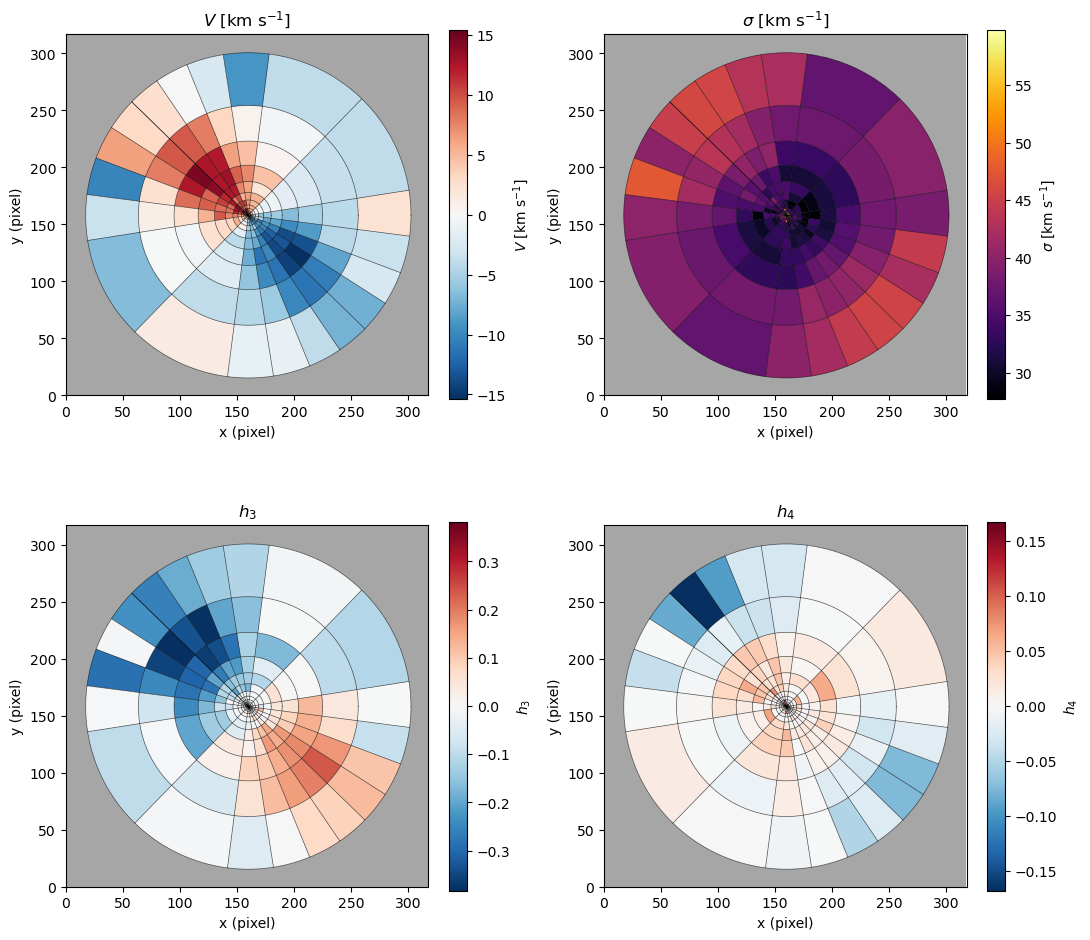

In [9]:
V = np.array([bin_data[b]["moments"]["vherm"] for b in bin_ids])
V -= np.nanmedian(V)  # remove the systemic velocity for plotting
SIGMA = np.array([bin_data[b]["moments"]["sherm"] for b in bin_ids])
H3 = np.array([bin_data[b]["moments"]["h3"] for b in bin_ids])
H3 -= np.nanmedian(H3)
H4 = np.array([bin_data[b]["moments"]["h4"] for b in bin_ids])

moment_names = ["V", "sigma", "h3", "h4"]
moment_labels = [r"$V$ [km s$^{-1}$]", r"$\sigma$ [km s$^{-1}$]", r"$h_3$", r"$h_4$"]
moment_vals = [V, SIGMA, H3, H4]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, name, label, vals in zip(axes.ravel(), moment_names, moment_labels, moment_vals):
    cmap = "inferno" if name == "sigma" else "RdBu_r"
    plot_bin_map(ax, bin_table, bins, dict(zip(bin_ids, vals)), center_pix=bins.center,
                 pa_deg=PA_DEG, pixel_scale=cube.pixel_scale, background=white_light,
                 cmap=cmap, colorbar_label=label)
    ax.set_xlim(0, nx); ax.set_ylim(0, ny)
    ax.set_title(label)
    ax.set_xlabel("x (pixel)"); ax.set_ylabel("y (pixel)")
plt.tight_layout(); plt.show()

## 7. Radial kinematic profiles -- V, sigma, h3, h4 along the major axis

The complementary view to the 2D maps above, and the one that actually
reads like a rotation curve: every bin's moment plotted against its own
*signed* distance along the kinematic major axis (positive on the receding
side, negative on the approaching side), restricted to a wedge of bins
close to that axis so the plotted points aren't smeared out across the
minor-axis direction where the LOSVD is dominated by dispersion, not
rotation. This is the same construction
`dev_notes/scratch_notebooks/ppxf_vs_kinextract_comparison.ipynb` uses for
its own axis-profile plot.

Because `assign_spaxels_to_bins` was called with `pa_deg=PA_DEG`, every
bin's own `theta_mid` is *already* measured relative to the major axis (its
own `theta=0`) -- so the signed distance along the axis and the
perpendicular distance away from it fall out directly as
`r_mid*cos(theta_mid)` and `r_mid*sin(theta_mid)`, no extra rotation
needed.

43 of 219 bins selected within 11.5 deg of the major axis


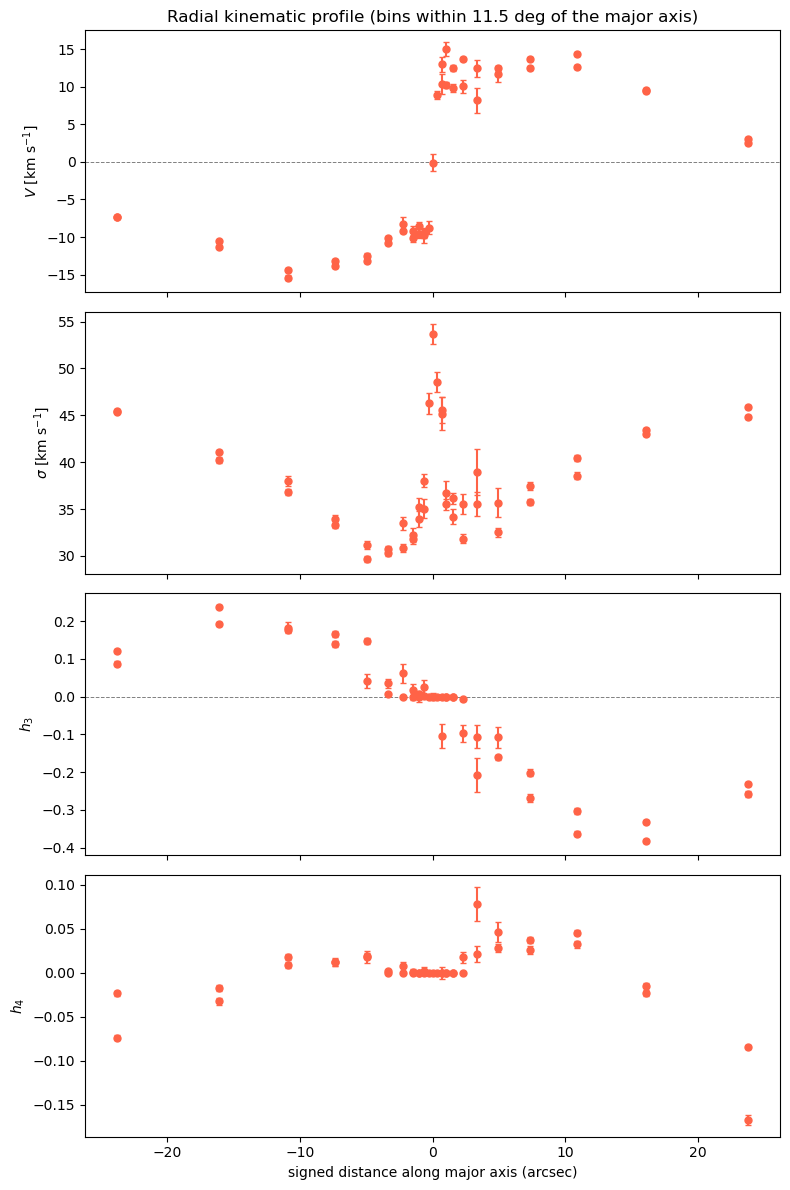

In [10]:
AXIS_HALF_WIDTH_DEG = 11.5  # angular wedge half-width around the major axis

r_signed = np.full(n_bins, 0.0)
d_perp = np.full(n_bins, 0.0)
is_center = np.zeros(n_bins, dtype=bool)
for i, bid in enumerate(bin_ids):
    bd = bin_data[bid]
    if bd["theta_mid"] is None:
        is_center[i] = True
        continue
    r_signed[i] = bd["r_mid"] * np.cos(bd["theta_mid"])
    d_perp[i] = bd["r_mid"] * np.sin(bd["theta_mid"])

# fold across the +/- axis direction (theta_mid near 0 or near pi are both "on axis")
phi_folded = np.minimum(np.abs(d_perp / np.maximum(np.array([bin_data[b]["r_mid"] for b in bin_ids]), 1e-6)),
                         1.0)
angle_from_axis_deg = np.degrees(np.arcsin(phi_folded))
axis_mask = (angle_from_axis_deg <= AXIS_HALF_WIDTH_DEG) | is_center

print(f"{axis_mask.sum()} of {n_bins} bins selected within {AXIS_HALF_WIDTH_DEG} deg of the major axis")

# y_limits = [(-18,18), (20, 80), (-0.4, 0.25), (-0.4, 0.4)]

fig, axes = plt.subplots(4, 1, figsize=(8, 12), sharex=True)
for ax, name, label, vals in zip(axes, moment_names, moment_labels, moment_vals):
    errs = np.array([bin_data[b].get(f"{'vherm' if name=='V' else 'sherm' if name=='sigma' else 'h3' if name=='h3' else 'h4'}_std", 0.0)
                      for b in bin_ids])
    m = axis_mask
    order = np.argsort(r_signed[m])
    ax.errorbar(r_signed[m][order], vals[m][order], yerr=errs[m][order],
                fmt="o", color="tomato", ms=5, capsize=2)
    if name == "V" or name == "h3":
        ax.axhline(0.0, color="gray", lw=0.7, ls="--")
    # ax.set_ylim(y_limits[moment_names.index(name)])
    ax.set_ylabel(label)
axes[-1].set_xlabel('signed distance along major axis (arcsec)')
axes[0].set_title(f"Radial kinematic profile (bins within {AXIS_HALF_WIDTH_DEG} deg of the major axis)")
plt.tight_layout(); plt.show()

## Limitations, honestly

- **`rho` is carried from a single different aperture** (measured in
  `07_noise_correlation.ipynb`), not re-measured per bin here -- real
  correlation strength may vary with S/N or radius, and this notebook does
  not check that.
- **No bias correction applied** (`apply_bias_correction=False`, the
  package default) -- `dev_notes/uncertainty/FINDINGS.md`'s own 4-gate
  acceptance test found the current calibration passes for sigma but not
  h4 (see that file for the full story); reported h3/h4 uncertainties
  here are the raw bootstrap spread, not corrected for regularization
  shrinkage.
- **Cleaning (`fit_losvd_clean_parallel`, robust-scaled) is now the
  default, but `CLIP_SIGMA`/`MAX_ITER` are a starting point, not a
  validated universal choice for every target.** Too aggressive a
  threshold risks clipping into real absorption features (the CaII
  triplet in particular); too lax leaves real contamination in. It also
  has no mechanism for a genuine continuum-*shape* mismatch (e.g. an
  imperfect sky subtraction that biases the local continuum level rather
  than adding a narrow spike) -- that isn't a per-pixel outlier problem,
  and no clip threshold fixes it. See `dev_notes/scratch_notebooks/
  cleaning_tuning.ipynb` for the tuning sandbox and what else was tried.
- **Real-data chi2_red on this target runs well above 1** (see
  `dev_notes/HISTORY.md`'s "Real-data behavior" entry and
  `07_noise_correlation.ipynb`) even after correlated-noise whitening and
  cleaning -- a real, only-partially-understood residual on top of
  everything this notebook applies. Treat the maps/profiles above as a
  demonstration of the full pipeline working end-to-end on real data at
  real scale, not a publication-ready NGC 5102 measurement.
- **Double-peaked/multi-component LOSVDs are not specifically handled.**
  This package's non-parametric spline recovery can represent them (unlike
  a fixed Gauss-Hermite parametrization), but no notebook in this sequence
  specifically validates that case -- worth building if a real target is
  expected to show one (e.g. a counter-rotating core or two kinematically
  distinct components along the line of sight).